In [6]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['axes.unicode_minus'] = False

conn = sqlite3.connect('../ecommerce.db')

def query(sql):
    """SQL 쿼리를 DataFrame으로 반환하는 헬퍼 함수"""
    return pd.read_sql(sql, conn)

1. 테이블 목록 & 행 수 확인

In [10]:
# 테이블 목록 확인
tables = query("""
    SELECT name FROM sqlite_master
    WHERE type='table'
    ORDER BY name
""")
print("테이블 목록")
print(tables)

# 각 테이블 행 수 확인
table_names = ['orders', 'order_items', 'customers',
               'products', 'sellers', 'payments', 'reviews', 'category_translation']

print("\n 테이블별 행 수")
for t in table_names:
    cnt = query(f"SELECT COUNT(*) as cnt FROM {t}")
    print(f" {t:25s}: {cnt['cnt'][0]:>10,} 행") # t:25s 문자열을 25칸으로 고정(왼쪽 정렬)
                                                # 값:>10 10칸, 오른쪽 정렬, 천 단위 콤마

테이블 목록
                   name
0  category_translation
1             customers
2           order_items
3                orders
4              payments
5              products
6               reviews
7               sellers

 테이블별 행 수
 orders                   :     99,441 행
 order_items              :    112,650 행
 customers                :     99,441 행
 products                 :     32,951 행
 sellers                  :      3,095 행
 payments                 :    103,886 행
 reviews                  :     99,224 행
 category_translation     :         71 행


2. 각 테이블 컬럼 & 샘플 확인

In [11]:
for t in table_names:
    print(f"=== {t} ===")
    display(query(f"SELECT * FROM {t} LIMIT 3"))

=== orders ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


=== order_items ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


=== customers ===


...

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71


=== reviews ===


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,None,None,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,None,None,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,None,None,2018-02-17 00:00:00,2018-02-18 14:36:24


=== category_translation ===


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


3. 데이터 기간 & 주문 상태 확인

In [14]:
print("데이터 기간")
display(query("""
    SELECT 
        MIN(order_purchase_timestamp) AS start_date,
        MAX(order_purchase_timestamp) AS end_date
    FROM orders
"""))

print("주문 상태 분포")
display(query("""
    SELECT 
        order_status,
        COUNT(*) AS count,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders), 2) AS pct
    FROM orders
    GROUP BY order_status
    ORDER BY count DESC
"""))

데이터 기간


,start_date,end_date
0,2016-09-04 21:15:19,2018-10-17 17:30:18


주문 상태 분포


,order_status,count,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


4. 결측치 확인

In [16]:
# 핵심 테이블 결측치 확인
key_tables = {
    'orders'     : query("SELECT * FROM orders"),
    'order_items': query("SELECT * FROM order_items"),
    'customers'  : query("SELECT * FROM customers"),
    'payments'   : query("SELECT * FROM payments"),
}

print("결측치 현황")
for name, df in key_tables.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if len(missing) > 0:
        print(f"\n[{name}]")
        print(missing)
    else:
        print(f"\n[{name}] - 결측치 없음!!")

결측치 현황

[orders]
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

[order_items] - 결측치 없음!!

[customers] - 결측치 없음!!

[payments] - 결측치 없음!!


5. 월별 주문 수 시각화
- 2016년은 서비스 초기로 데이터가 불안정하여 2017-01-01 이후 데이터만 사용
- 201609 (3건), 201610 (324건), 201612 (2건), 201701(800건), 201702(1780건) ...

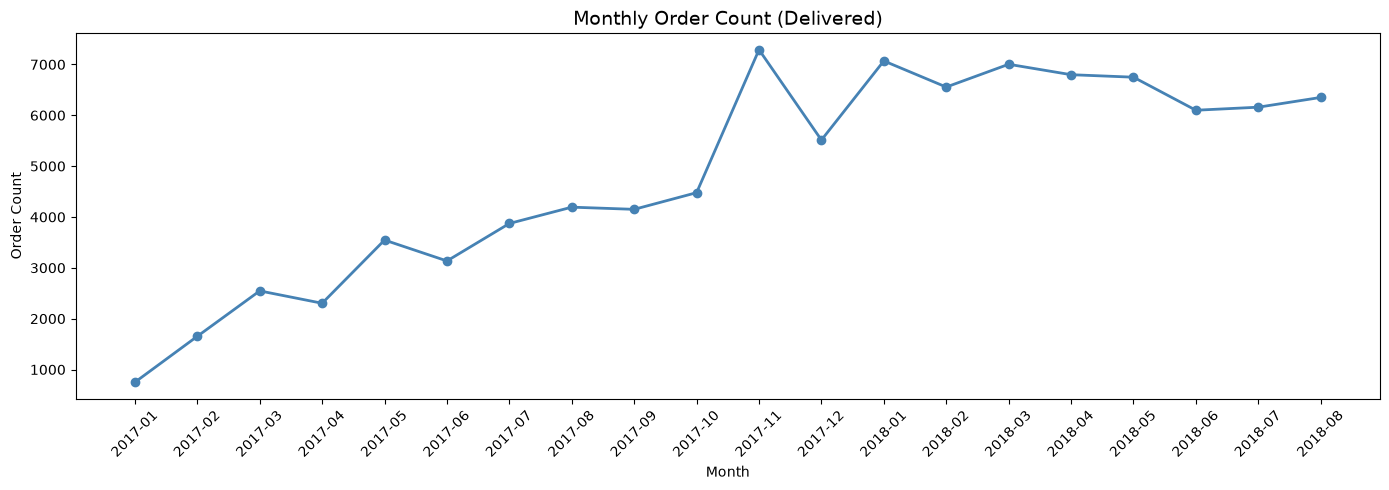

In [18]:
monthly_orders = query("""
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(*) AS order_count
    FROM orders
    WHERE order_status = 'delivered' AND order_purchase_timestamp >= '2017-01-01' --데이터 안정 구간
    GROUP BY month
    ORDER BY month
""")

plt.figure(figsize=(14,5))
plt.plot(monthly_orders['month'], monthly_orders['order_count'],
         marker='o', linewidth=2, color='steelblue')
plt.xticks(rotation=45)
plt.title('Monthly Order Count (Delivered)', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Order Count')
plt.tight_layout()
plt.savefig('../output/monthly_orders.png', dpi=150)
plt.show()

6. 결제 금액 분포

C:\Users\926174\AppData\Local\Temp\ipykernel_8532\3437992523.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(payments_df['payment_value'], vert=False)


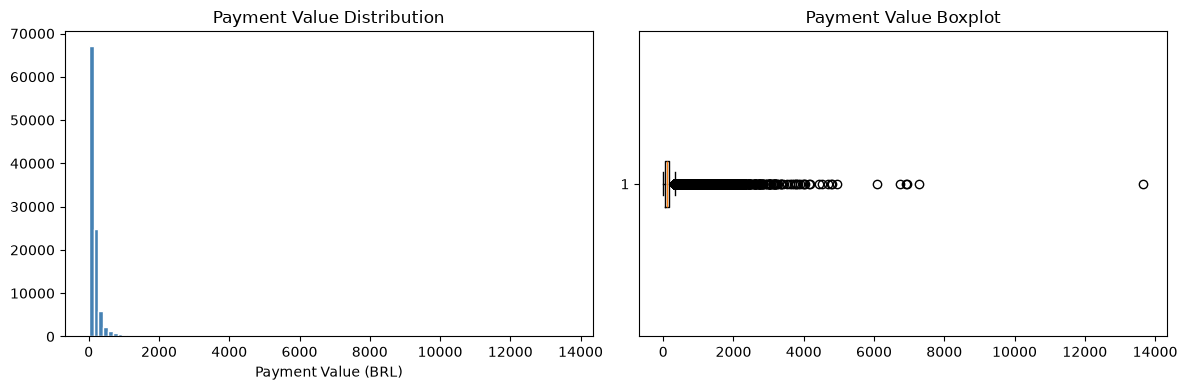

count    103877.00
mean        154.11
std         217.50
min           0.01
25%          56.82
50%         100.00
75%         171.84
max       13664.08
Name: payment_value, dtype: float64


In [19]:
payments_df = query("SELECT payment_value FROM payments WHERE payment_value > 0")

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(payments_df['payment_value'], bins=100, color='steelblue', edgecolor='white')
plt.title('Payment Value Distribution')
plt.xlabel('Payment Value (BRL)')

plt.subplot(1,2,2)
plt.boxplot(payments_df['payment_value'], vert=False)
plt.title('Payment Value Boxplot')

plt.tight_layout()
plt.savefig('../output/payment_distribution.png', dpi=150)
plt.show()

# 기술통계
print(payments_df['payment_value'].describe().round(2))

- 결제 금액 분포
    - 중앙값 100 BRL, 평균 154 BRL → 오른쪽 꼬리 분포
    - 평균이 중앙값보다 54% 높아 고액 이상치가 평균을 왜곡
    - 이후 매출 분석 시 평균보다 중앙값 또는 분포 기반 해석 권장
    - IQR 기준 이상치 상한선: 약 344 BRL (전체의 약 10% 해당)